<a href="https://colab.research.google.com/github/DingiestParrot221103/UniMastersWork2026-27/blob/git-checkout--b-%3CUni_AppliedAI%3E/COM7017_WEEK_5_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

In [ ]:
iris = load_iris(as_frame=True)

X_df = iris.data.copy()
species = iris.target.copy()

print(X_df.head())
print("Shape:", X_df.shape)
print("Missing values:", X_df.isna().sum().sum())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Shape: (150, 4)
Missing values: 0


**Why should species labels be excluded when fitting an unsupervised model?**
Unsupervised method is designed to discover patterns and groups, not be correct. Including labels would defeat the purpose

**Which features are measured in centimetres?**
All 4 features

In [ ]:
print("Nulls by column:\n", X_df.isna().sum())

print("Exact duplicate rows:", X_df.duplicated().sum())

X_clean = X_df.fillna(X_df.median(numeric_only=True))

Nulls by column:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64
Exact duplicate rows: 1


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_clean)

print("Shape after scaling:", X_scaled.shape)

print("Column means:", np.round(X_scaled.mean(axis=0), 2))

print("Column SDs:", np.round(X_scaled.std(axis=0), 2))

Shape after scaling: (150, 4)
Column means: [-0. -0. -0. -0.]
Column SDs: [1. 1. 1. 1.]


**Does standardisation change the number of observations or columns?**
No, it changes the scale of numerical values - not the number of observations

**Why should a student ID not be used as a numerical clustering feature?**
It's an identifier, not a measurement. Including it could cause the algorithm to group students based off ID not data similarities


In [ ]:
a = X_clean.iloc[0].to_numpy(dtype=float)
b = X_clean.iloc[1].to_numpy(dtype=float)

print("Record a:", a)
print("Record b:", b)

Record a: [5.1 3.5 1.4 0.2]
Record b: [4.9 3.  1.4 0.2]


In [ ]:
euclidean = np.sqrt(np.sum((a - b)**2))

manhattan = np.sum(np.abs(a - b))

print("Euclidean:", round(euclidean, 4))
print("Manhattan:", round(manhattan, 4))

Euclidean: 0.5385
Manhattan: 0.7


In [ ]:
from scipy.spatial.distance import euclidean as euclid_fn
from scipy.spatial.distance import cityblock

print("SciPy Euclidean:", round(euclid_fn(a, b), 4))

print("SciPy Manhattan:", round(cityblock(a, b), 4))

SciPy Euclidean: 0.5385
SciPy Manhattan: 0.7


In [ ]:
a_scaled = X_scaled[0]
b_scaled = X_scaled[1]

euclidean_scaled = np.sqrt(np.sum((a_scaled - b_scaled)**2))

manhattan_scaled = np.sum(np.abs(a_scaled - b_scaled))

print("Scaled Euclidean:", round(euclidean_scaled, 4))

print("Scaled Manhattan:", round(manhattan_scaled, 4))

Scaled Euclidean: 1.1762
Scaled Manhattan: 1.3933


**Which distance is the straight-line distance**
Euclidean distance

**Why might changing feature scales change which points are considered close?**
Larger values have a greater influence on distance calculations. Standardisation prevents this VIA placing features on a scale

In [ ]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)

k_labels = kmeans.fit_predict(X_scaled)

print("Cluster counts:", np.bincount(k_labels))

print("Inertia:", round(kmeans.inertia_, 2))

Cluster counts: [53 50 47]
Inertia: 139.82


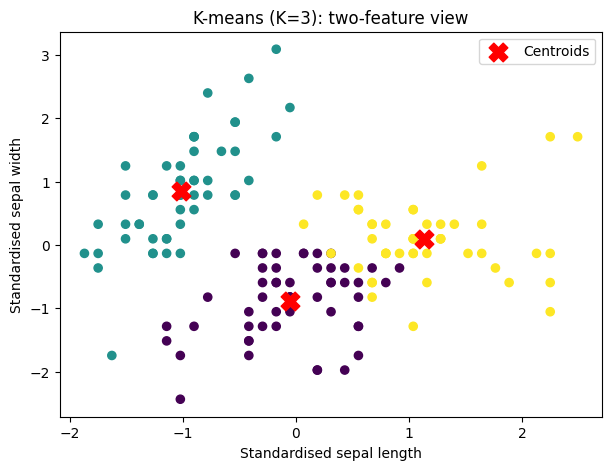

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=k_labels,
    cmap="viridis",
    s=35
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    c="red",
    s=180,
    label="Centroids"
)

plt.xlabel("Standardised sepal length")
plt.ylabel("Standardised sepal width")

plt.title("K-means (K=3): two-feature view")

plt.legend()
plt.show()

In [ ]:
other = KMeans(n_clusters=3, n_init=10, random_state=10)

other.fit(X_scaled)

print("Other inertia:", round(other.inertia_, 2))

Other inertia: 139.82


**What is a centroid?**
Central point of the cluster, calculated using average values of datagroup

**Why can the plot overlap even when clustering uses four features?**
Graph only displays 2(/4) features - other 2 features help seperate clusters even when they overlap

**Does cluster label 0 automatically correspond to a particular flower species?**
No, assigned by algorithm

In [ ]:
k_values = range(2, 9)

inertias, silhouettes = [], []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)

    silhouettes.append(silhouette_score(X_scaled, labels))

for k, i, s in zip(k_values, inertias, silhouettes):
    print(f"K={k}: inertia={i:.2f}, silhouette={s:.3f}")

K=2: inertia=222.36, silhouette=0.582
K=3: inertia=139.82, silhouette=0.460
K=4: inertia=114.09, silhouette=0.387
K=5: inertia=90.93, silhouette=0.346
K=6: inertia=81.54, silhouette=0.317
K=7: inertia=72.63, silhouette=0.320
K=8: inertia=62.54, silhouette=0.339


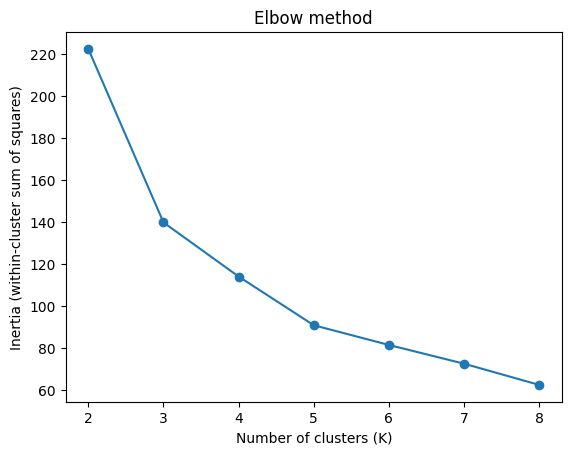

In [ ]:
plt.plot(list(k_values), inertias, marker="o")

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (within-cluster sum of squares)")

plt.title("Elbow method")

plt.show()

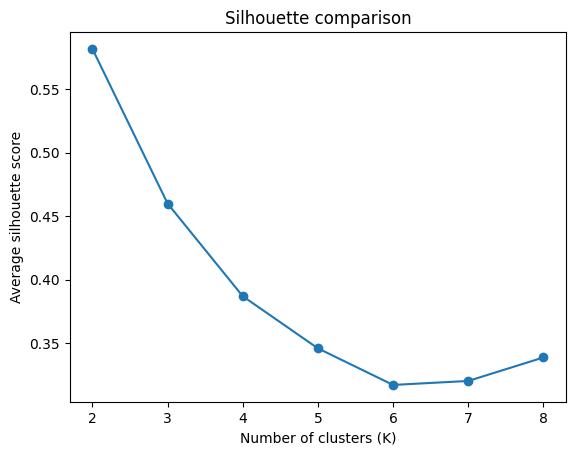

In [ ]:
plt.plot(list(k_values), silhouettes, marker="o")

plt.xlabel("Number of clusters (K)")
plt.ylabel("Average silhouette score")

plt.title("Silhouette comparison")

plt.show()

**Which K has the highest silhouette score?**
highest silhouette score  achieved K = 4, score of ~ 118.
suggests that this number of clusters provides the best separation between groups among values tested

**Compare the silhouette score with the elbow graph. Why might they disagree?**
Elbow method focuses on reducing inertia, silhouette measures how well seperated clusters are. They differ because they measure seperate things

**Why does inertia decrease when K increases, and why isn't the largest K automatically best?**
Inertia reduces because the data values tend to come together closer to the cluster centres. Using too many clusters tend to create unnecessary groups and reduce usefulness of results

In [ ]:
agg = AgglomerativeClustering(n_clusters=3, linkage="ward")

h_labels = agg.fit_predict(X_scaled)

print("Cluster sizes:", np.bincount(h_labels))

Cluster sizes: [71 49 30]


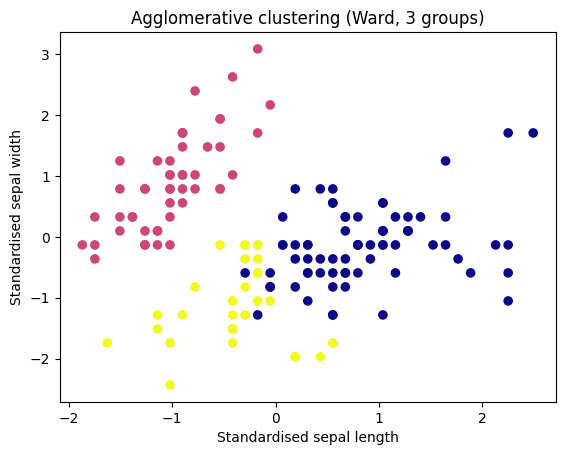

In [ ]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=h_labels,
    cmap="plasma",
    s=35
)

plt.xlabel("Standardised sepal length")
plt.ylabel("Standardised sepal width")

plt.title("Agglomerative clustering (Ward, 3 groups)")

plt.show()

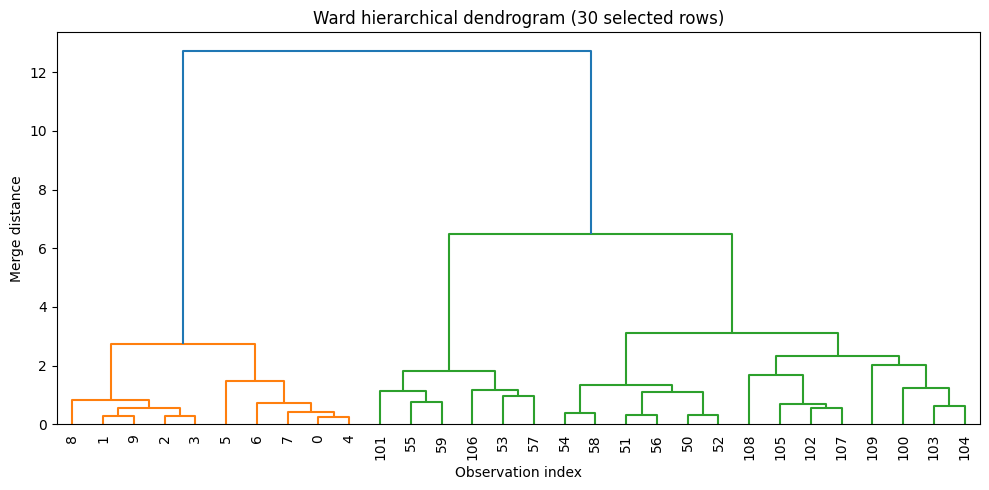

In [ ]:
indices = np.r_[0:10, 50:60, 100:110]

subset = X_scaled[indices]

Z = linkage(subset, method="ward", metric="euclidean")

plt.figure(figsize=(10, 5))

dendrogram(
    Z,
    labels=[str(i) for i in indices],
    leaf_rotation=90
)

plt.xlabel("Observation index")
plt.ylabel("Merge distance")

plt.title("Ward hierarchical dendrogram (30 selected rows)")

plt.tight_layout()
plt.show()

In [ ]:
for method in ["ward", "complete", "single"]:
    m = AgglomerativeClustering(
        n_clusters=3,
        linkage=method
    )

    labels = m.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"{method}: silhouette={score:.3f}")

ward: silhouette=0.447
complete: silhouette=0.450
single: silhouette=0.505


**What does the vertical height of a dendrogram merge mean?**
Vertical height represents distance between 2 clusters when they're combined. Greater height indicates merged clusters are dissimilar

**Explain why linkage methods may form different groups**
Uses different combinations, representing different structures

**What is the main difference between K-means and agglomerative clustering?**
K mean divides data into specified number of clusters w/ centroid - Agglomerative starts with indiviual data points and merges them with bottom up approach

**Which linkage may be sensitive to chaining**
Single Linkage

**Why use 30 points rather than all 150 in the demonstration dendrogram**
Graph is easy to read, 150 would be cluttered

In [ ]:
for name, labels in [
    ("K-means", k_labels),
    ("Agglomerative (Ward)", h_labels)
]:
    sil = silhouette_score(X_scaled, labels)

    db = davies_bouldin_score(X_scaled, labels)

    print(f"{name}: silhouette={sil:.3f}; DB={db:.3f}")

K-means: silhouette=0.460; DB=0.834
Agglomerative (Ward): silhouette=0.447; DB=0.803


**Why do the numerical cluster labels not need to match between algorithms?**

Because cluster numbers are assigned arbitrarily by each algorithm. Cluster 0 in K-means does not necessarily represent the same group as cluster 0 in Agglomerative clustering.

**Why is a good internal score not proof of useful or fair clusters?**

Because internal evaluation scores only measure mathematical properties of the clusters. They do not guarantee that the groups are meaningful, useful or fair in real-world applications.

**What effect might an outlier have on your results?**

An outlier can distort distance calculations and affect cluster centres, potentially resulting in less accurate or less representative clusters.